# Figure S13: Lead-variant PIP and causal resolution

Restore the current EAS density curves, mean lead PIP, and percentage above PIP 0.9 from saved plot data.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The notebook reads the recorded figure data.
It does not rerun upstream QTL mapping unless a section explicitly says so.
New PDFs and PNGs go to `notebook_outputs/`. Inputs stay in place.
The source scripts are in `notebooks/current/`. Figures shown below are aggregate
plots. Do not print participant tables into a saved notebook.


## Scope

Density coordinates and their bandwidth choices remain those in the saved display. No density estimation or fine-mapping is repeated.

The high-PIP percentage uses a strict PIP > 0.9 cutoff. Population fits can contain different detected signals.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the November 2 figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display the archived November 2 submission image for Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the saved EAS PIP panels

Restore S13 from the current density curves and summaries. This notebook does not estimate new densities or run fine-mapping. The density grid contains saved display coordinates, not variant records.


In [2]:
saved <- readRDS(paper_file("Supplemental Figures/01_Supplemental_drafts/Figure1_population_lead_PIP/v2_with_EAS/figure_display.rds"))
stopifnot(all(c("A", "B", "C", "summary") %in% names(saved)),
          "EAS" %in% as.character(saved$summary$population),
          all(dplyr::between(saved$A$data$pip, 0, 1)))


## Restore density and summary panels

Panel A shows the saved lead-PIP densities. Panels B and C show the mean lead PIP and the percentage with lead PIP strictly greater than 0.9. Population analyses can contain different detected credible sets.


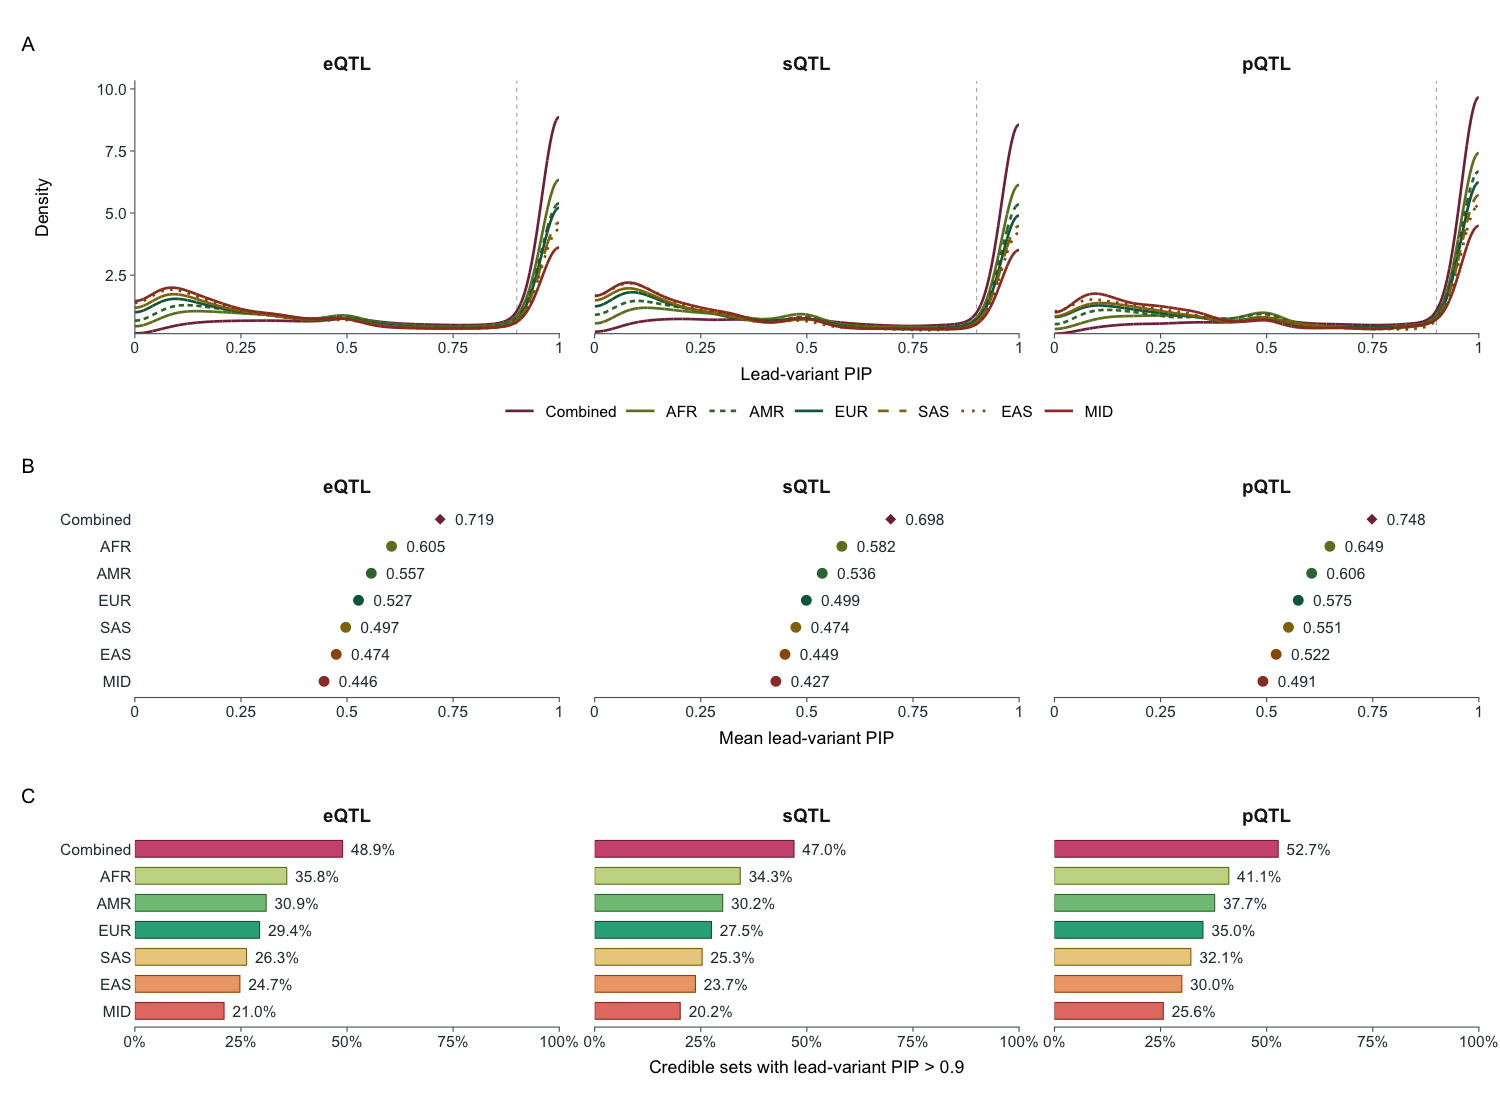

In [3]:
figure <- (saved$A + labs(title = NULL, subtitle = NULL)) /
  (saved$B + labs(title = NULL, subtitle = NULL)) /
  (saved$C + labs(title = NULL, subtitle = NULL)) +
  patchwork::plot_layout(heights = c(1.3, 1, 1)) + patchwork::plot_annotation(tag_levels = "A")
print(figure)


## Save aggregate outputs

Save the figure and population summaries. Percentages use a 0–100 scale.


In [4]:
save_plot(figure, "supplements/S13", 184, 210)
readr::write_tsv(saved$summary, output_file("supplements/S13_summary.tsv"))


Export aggregate plot: supplements/S13
